In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast

ANIMAL_FILE = "data/animal_data_dirty1.csv"
MOVIES_FILE = "data/movies_metadata.csv"
CREDITS_FILE = "data/credits.csv"

df = pd.read_csv(ANIMAL_FILE, sep=';')
movies = pd.read_csv(MOVIES_FILE, low_memory=False)
credits = pd.read_csv(CREDITS_FILE)

# Task 1

(1011, 11)
       Animal type Country  Weight kg  Body Length cm          Gender  Animal code   Latitude  Longitude Animal name Observation date  \
0              NaN     NaN        NaN             NaN             NaN          NaN        NaN        NaN         NaN       03.01.2024   
1              NaN     NaN        NaN             NaN             NaN          NaN        NaN        NaN         NaN       03.02.2024   
2   European bison  Poland      930.0           335.0            male          NaN  52.828845  23.820144       Szefu       01.03.2024   
3   European bison  Poland      909.0           311.0  not determined          NaN  52.830509  23.826849         NaN       01.03.2024   
4  European bison™  Poland      581.0           277.0          female          NaN  52.834109  23.807093         NaN       01.03.2024   

  Data compiled by  
0    James Johnson  
1    James Johnson  
2     Anne Anthony  
3     Anne Anthony  
4     Anne Anthony  
<class 'pandas.core.frame.DataFrame'>
Ra

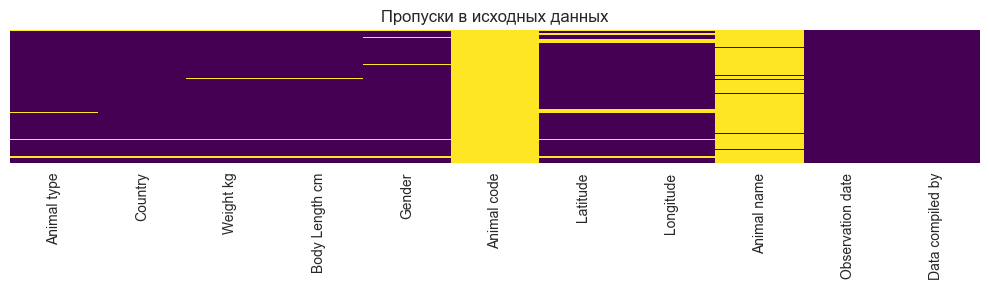

Дубликатов: 167


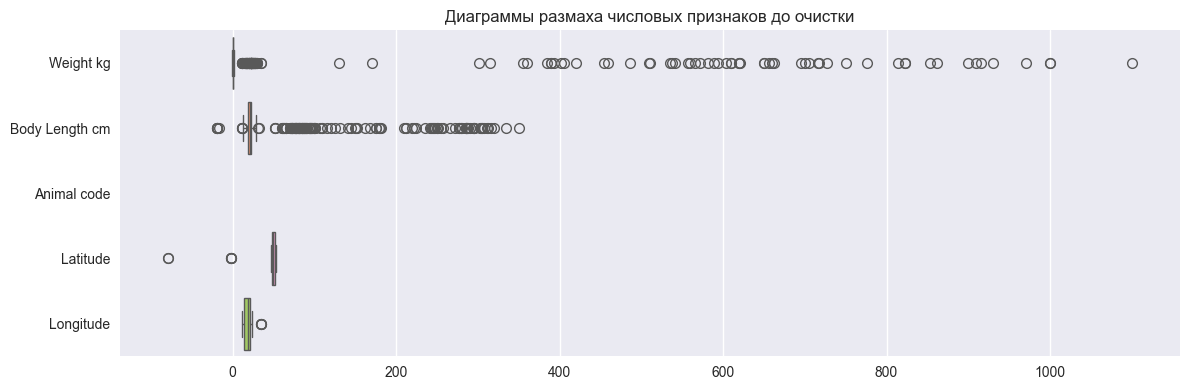

In [27]:
print(df.shape)
print(df.head())
print(df.info())
print(df.isna().sum())

plt.figure(figsize=(10, 3))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title("Пропуски в исходных данных")
plt.tight_layout()
plt.show()

print("Дубликатов:", df.duplicated().sum())

num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
if num_cols:
    plt.figure(figsize=(12, 4))
    sns.boxplot(data=df[num_cols], orient="h")
    plt.title("Диаграммы размаха числовых признаков до очистки")
    plt.tight_layout()
    plt.show()

In [28]:
df_clean = df.copy()

for col in df_clean.columns:
    if df_clean[col].dtype == "object":
        df_clean[col] = df_clean[col].astype(str).str.strip()
        df_clean[col] = df_clean[col].replace({"nan": np.nan, "None": np.nan, "": np.nan})

for col in df_clean.columns:
    if pd.api.types.is_numeric_dtype(df_clean[col]):
        if df_clean[col].notna().sum() > 0:
            df_clean[col] = df_clean[col].fillna(df_clean[col].median())
        else:
            df_clean[col] = df_clean[col].fillna(0)
    else:
        mode_val = df_clean[col].mode(dropna=True)
        if len(mode_val) > 0:
            df_clean[col] = df_clean[col].fillna(mode_val[0])
        else:
            df_clean[col] = df_clean[col].fillna("Unknown")

df_clean = df_clean.drop_duplicates().reset_index(drop=True)

numeric_cols = df_clean.select_dtypes(include=[np.number]).columns.tolist()
numeric_cols = [col for col in numeric_cols if df_clean[col].notna().sum() > 0]

for col in numeric_cols:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = df_clean[col].between(lower, upper)
    df_clean.loc[~mask, col] = df_clean[col].median()

In [29]:
for col in numeric_cols:
    if (df_clean[col] < 0).any():
        print(f"- Отрицательные значения в {col}")

print(f"Размер после очистки: {df_clean.shape}")

if numeric_cols:
    print(df_clean[numeric_cols].describe())

- Отрицательные значения в Weight kg
Размер после очистки: (844, 11)
        Weight kg  Body Length cm  Animal code    Latitude   Longitude
count  844.000000      844.000000        844.0  844.000000  844.000000
mean     0.466573       20.381517          0.0   49.719602   17.745471
std      0.267008        2.360497          0.0    1.745721    3.682938
min     -0.252000       13.000000          0.0   47.316383   11.074008
25%      0.298750       19.000000          0.0   48.231366   14.382216
50%      0.344000       21.000000          0.0   49.560723   18.939968
75%      0.600000       22.000000          0.0   50.643518   20.557719
max      1.200000       29.000000          0.0   52.853843   23.919668


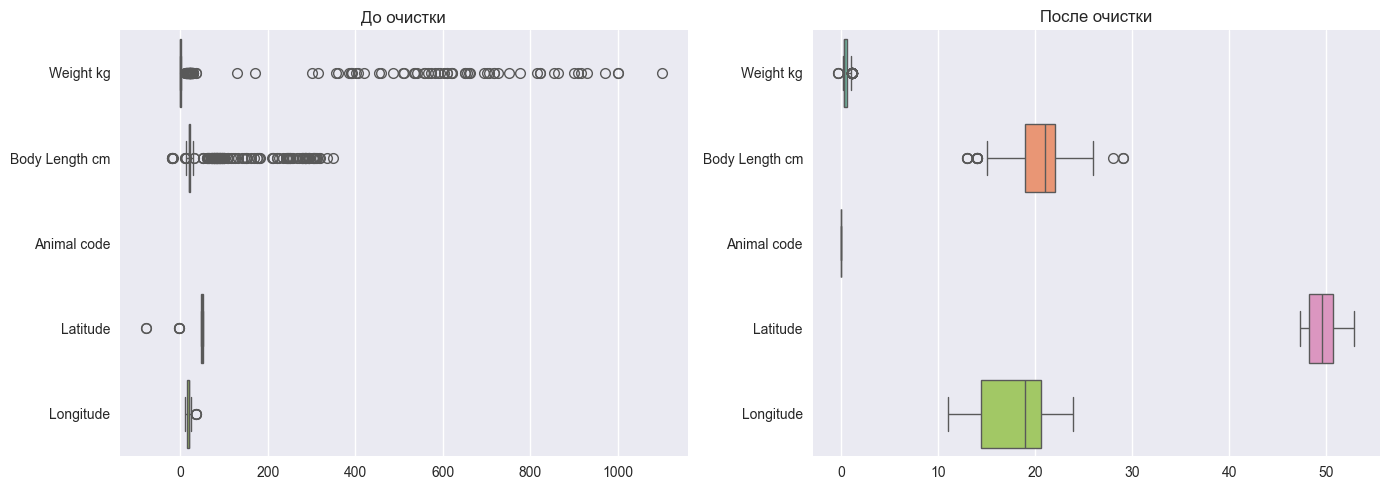

In [30]:
if numeric_cols:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.boxplot(data=df[numeric_cols], orient="h", ax=axes[0])
    axes[0].set_title("До очистки")
    sns.boxplot(data=df_clean[numeric_cols], orient="h", ax=axes[1])
    axes[1].set_title("После очистки")
    plt.tight_layout()
    plt.show()

# Task 2

In [31]:
movies_simple = movies[['id', 'title', 'vote_average', 'genres']].copy()
movies_simple['id'] = pd.to_numeric(movies_simple['id'], errors='coerce')
movies_simple = movies_simple.dropna(subset=['id'])

credits['id'] = pd.to_numeric(credits['id'], errors='coerce')
credits = credits.dropna(subset=['id'])

df_merged = movies_simple.merge(credits[['id', 'crew']], on='id', how='inner')

In [32]:
def get_director(crew_str):
    if pd.isna(crew_str):
        return np.nan
    try:
        crew = ast.literal_eval(crew_str)
        for person in crew:
            if person.get('job') == 'Director':
                return person.get('name')
    except:
        pass
    return np.nan

def get_genres(genres_str):
    if pd.isna(genres_str):
        return np.nan
    try:
        genres = ast.literal_eval(genres_str)
        return ', '.join([g['name'] for g in genres if 'name' in g][:3])
    except:
        return np.nan

df_merged['director'] = df_merged['crew'].apply(get_director)
df_merged['genre'] = df_merged['genres'].apply(get_genres)

result_df = df_merged[['title', 'director', 'genre', 'vote_average']].dropna(subset=['vote_average'])
result_df.columns = ['movie_title', 'director', 'genre', 'vote_average']

In [33]:
director_stats = result_df.dropna(subset=['director']).groupby('director')['vote_average'].agg(['mean', 'median', 'count']).reset_index()
director_stats = director_stats[director_stats['count'] >= 3].sort_values('mean', ascending=False)

print("Топ-10 режиссёров:")
print(director_stats.head(10))
print("\nХудшие:")
print(director_stats.tail(5))

Топ-10 режиссёров:
                 director      mean  median  count
8360          Jonas Mekas  8.900000    8.80      4
8388        Jonathan Hock  8.833333    9.50      3
2975      Claude Lanzmann  8.366667    8.70      3
13462          Raj Kapoor  8.366667    9.00      3
5069       Franco Piavoli  8.350000    8.45      4
9699             Lav Diaz  8.225000    8.40      4
11489        Michael Snow  8.100000    8.15      4
4153       Don Hertzfeldt  8.066667    8.10      6
6229      Henning Carlsen  8.033333    7.50      3
12643  Patrick Bokanowski  8.000000    8.30      3

Худшие:
             director  mean  median  count
1482    B. S. Johnson   0.0     0.0      4
11758   Mircea Veroiu   0.0     0.0      3
10543  Mariano Ozores   0.0     0.0      3
10585  Mario Pinzauti   0.0     0.0      3
8083      John Gorrie   0.0     0.0      4


In [34]:
genre_expanded = result_df.dropna(subset=['genre']).copy()
genre_expanded['genre_split'] = genre_expanded['genre'].apply(lambda x: x.split(', '))
genre_expanded = genre_expanded.explode('genre_split')

genre_stats = genre_expanded.groupby('genre_split')['vote_average'].agg(['mean', 'median', 'count']).reset_index()
genre_stats.columns = ['genre', 'mean', 'median', 'count']
genre_stats = genre_stats[genre_stats['count'] >= 10].sort_values('mean', ascending=False)

print("Топ-10 жанров:")
print(genre_stats.head(10))
print("\nХудшие:")
print(genre_stats.tail(5))

Топ-10 жанров:
          genre      mean  median  count
3     Animation  6.276116    6.50   1926
11      History  6.125178    6.50   1267
19          War  6.008348    6.30   1138
7         Drama  5.904406    6.20  19997
13        Music  5.882800    6.40   1500
5         Crime  5.867564    6.20   3974
6   Documentary  5.820525    6.60   3927
14      Mystery  5.795071    6.00   2110
10      Foreign  5.790023    6.10   1313
15      Romance  5.787791    6.05   6102

Худшие:
              genre      mean  median  count
16  Science Fiction  5.285053     5.5   2529
12           Horror  5.216905     5.4   4537
17         TV Movie  5.172131     5.7    671
20          Western  5.100867     5.7    923
0                    4.242179     5.0   2442


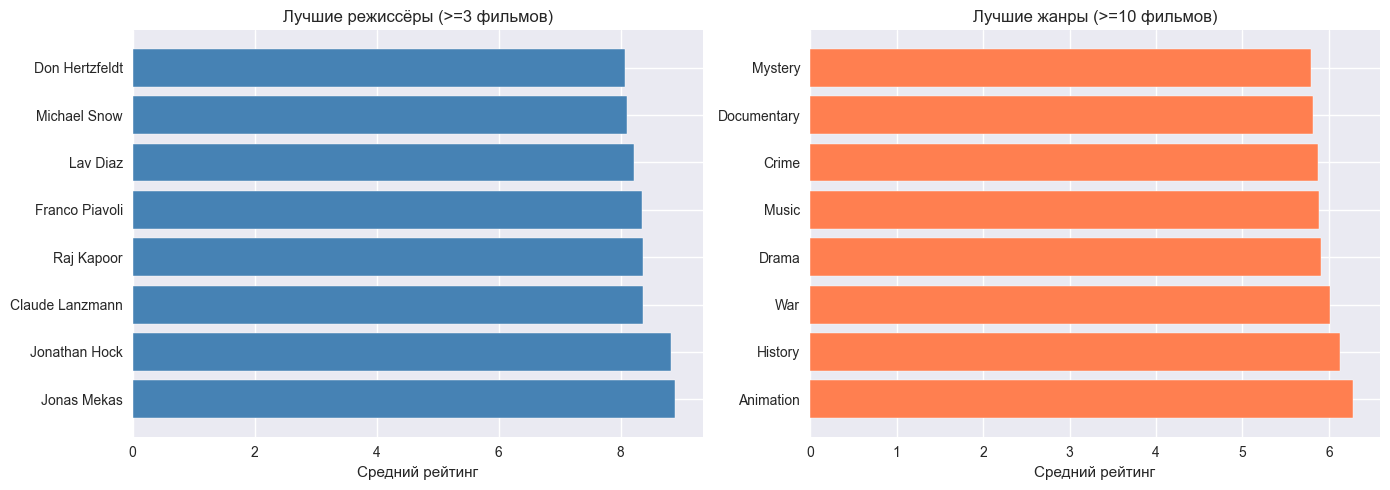

In [35]:
# не то чтобы это было нужно, но если аналитики любят красивые графики - почему бы и да)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

director_top = director_stats.head(8)
axes[0].barh(director_top['director'], director_top['mean'], color='steelblue')
axes[0].set_title('Лучшие режиссёры (>=3 фильмов)')
axes[0].set_xlabel('Средний рейтинг')

genre_top = genre_stats.head(8)
axes[1].barh(genre_top['genre'], genre_top['mean'], color='coral')
axes[1].set_title('Лучшие жанры (>=10 фильмов)')
axes[1].set_xlabel('Средний рейтинг')

plt.tight_layout()
plt.show()